# Pickup-and-delivery route optimization
**Jihad Boussata** · Python · MILP · operations research

A reproducible example of one vehicle serving four requests, with capacity and pickup-before-delivery requirements. Developed from my UGR MACE optimization coursework. The original model and instance are preserved; reusable code, independent checks and a heuristic comparison are added.

The default solver is HiGHS through SciPy. Install the repository first (`pip install -r requirements.txt` and `pip install --no-deps -e .`). Open this notebook from the repository or its `notebooks/` folder. See the [README](../README.md) and [formulation](../docs/MODEL.md) for assumptions and commands.

In [1]:
from pathlib import Path
import os
import json
from IPython.display import Image, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
assert (root / "data/four_requests.json").exists(), "Run from this repository."
os.chdir(root)

from pickup_delivery import load_instance, solve, evaluate_route
from pickup_delivery.baselines import nearest_feasible, exhaustive_reference
from pickup_delivery.plots import plot_solution

instance = load_instance("data/four_requests.json")
print("Capacity:", instance.capacity)
for request in instance.requests:
    print(f"Pickup {request.pickup} -> delivery {request.delivery}: {request.quantity:g} units")

Capacity: 5.0
Pickup 1 -> delivery 8: 2 units
Pickup 2 -> delivery 6: 3 units
Pickup 3 -> delivery 7: 2 units
Pickup 4 -> delivery 5: 1 units


## Solve the MILP
Arc variables select the route, MTZ constraints remove disconnected subtours, explicit precedence constraints order each pair, and post-service loads enforce capacity. The solver reports its status and gap; the route is checked separately before it is returned.

In [2]:
solution = solve(instance)
assert solution.status == "optimal"
print("Status:", solution.status)
print("Route:", " -> ".join(map(str, solution.route)))
print(f"Distance: {solution.distance:.10f} coordinate units")
print("Load after each stop:", solution.loads)
print("Relative MIP gap:", solution.relative_gap)

Status: optimal
Route: 0 -> 4 -> 1 -> 5 -> 2 -> 6 -> 3 -> 7 -> 8 -> 0
Distance: 39.1757429352 coordinate units
Load after each stop: [0.0, 1.0, 3.0, 2.0, 5.0, 2.0, 4.0, 2.0, 0.0, 0.0]
Relative MIP gap: 0.0


## Check independently and compare
The checker reads the route sequence rather than trusting the optimization variables. Exhaustive enumeration tests every one of the 8! customer orders and does not use the MILP. The nearest-feasible baseline chooses the nearest currently admissible stop, with node-ID tie-breaking.

In [3]:
checked = evaluate_route(instance, solution.route)
greedy = nearest_feasible(instance)
exact = exhaustive_reference(instance)
assert abs(exact["best"]["distance"] - solution.distance) < 1e-6
reduction = 100 * (1 - solution.distance / greedy["distance"])
print("Permutations checked:", exact["permutations_checked"])
print("Feasible routes:", exact["feasible_routes"])
print(f"Greedy distance: {greedy['distance']:.4f}")
print(f"Distance reduction vs greedy: {reduction:.2f}%")

Permutations checked: 40320
Feasible routes: 864
Greedy distance: 43.1718
Distance reduction vs greedy: 9.26%


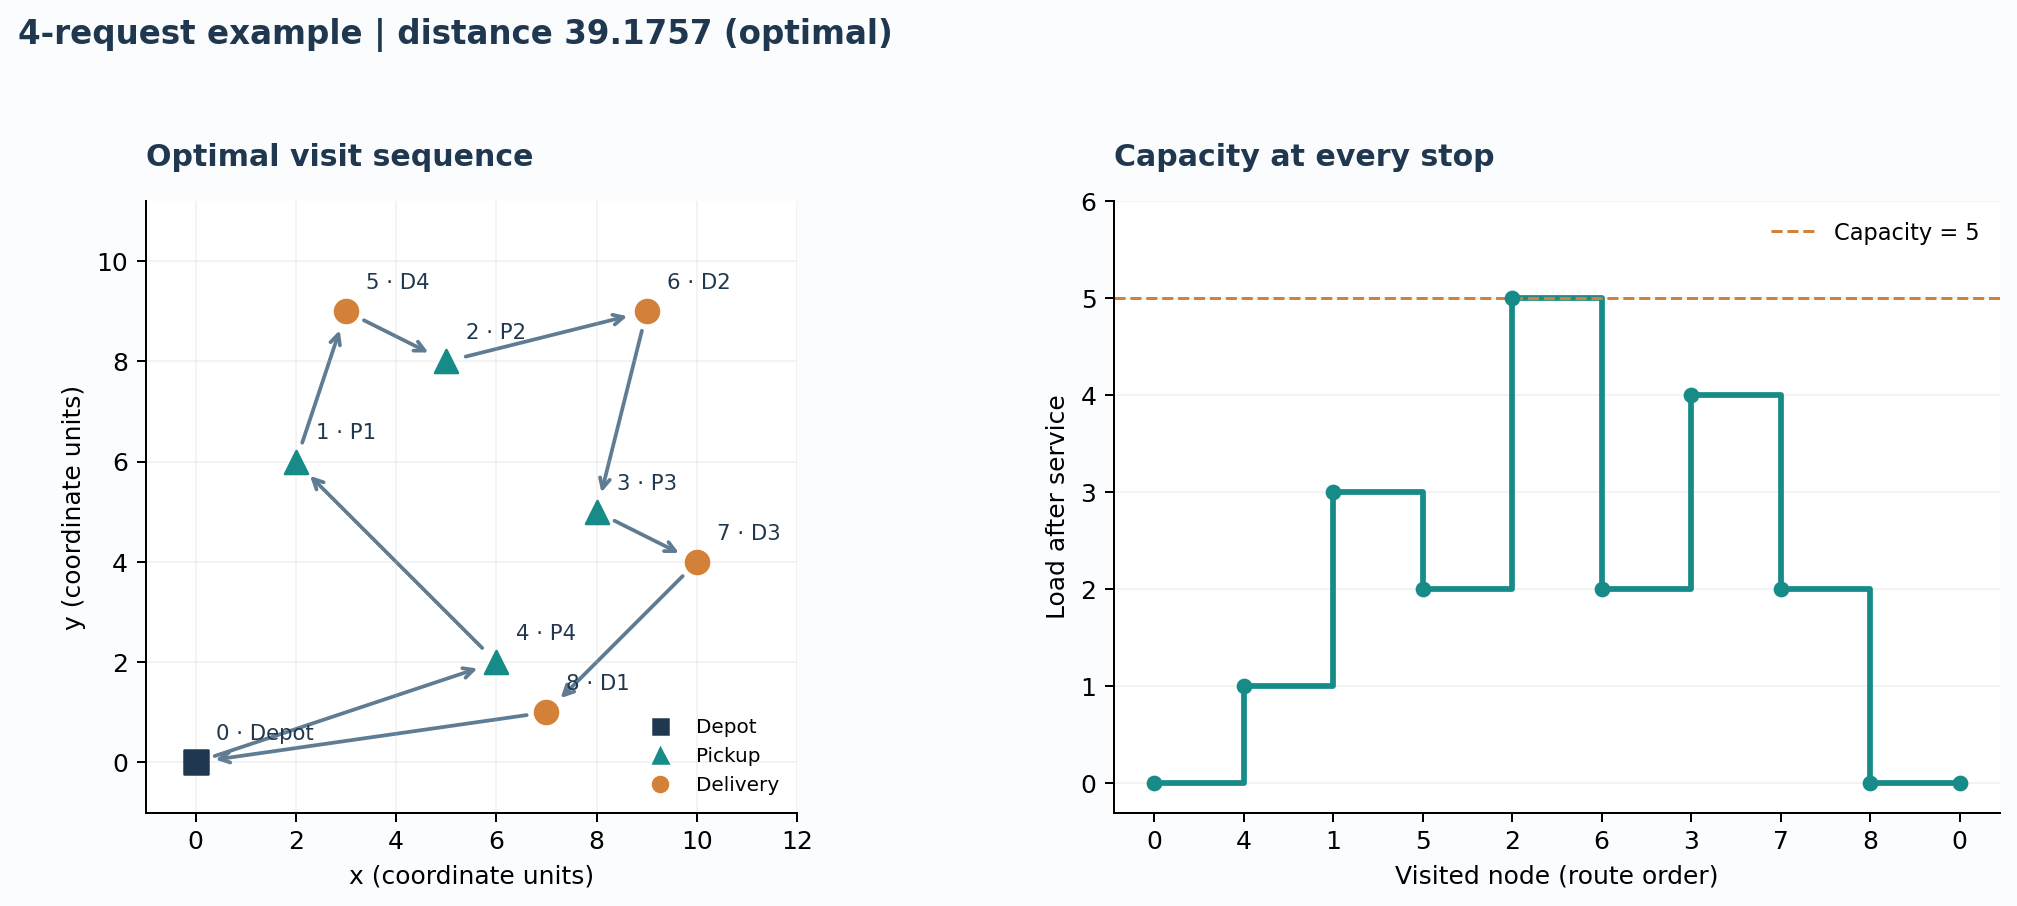

In [4]:
output = Path("results-local")
output.mkdir(exist_ok=True)
plot_solution(instance, solution, output / "notebook_route.png")
display(Image(filename=str(output / "notebook_route.png")))

## Capacity sensitivity
Only capacity changes; coordinates and request pairs stay fixed. Every tested case is checked against independent exhaustive enumeration. Capacity 2 cannot carry the request with quantity 3.

In [5]:
for capacity in range(2, 9):
    varied = instance.with_capacity(capacity)
    answer = solve(varied)
    reference = exhaustive_reference(varied)
    if reference["best"] is None:
        assert answer.status == "infeasible"
    else:
        assert abs(answer.distance - reference["best"]["distance"]) < 1e-6
    distance = "n/a" if answer.distance is None else f"{answer.distance:.4f}"
    print(f"Q={capacity}: {answer.status:10s} distance={distance}")

Q=2: infeasible distance=n/a
Q=3: optimal    distance=45.8286
Q=4: optimal    distance=45.3252
Q=5: optimal    distance=39.1757
Q=6: optimal    distance=39.1757
Q=7: optimal    distance=39.1757
Q=8: optimal    distance=39.1757


## Interpretation and limits
The optimum reproduces the original coursework result, while a documented greedy comparison makes the benefit measurable. Extra capacity helps up to 5 units on this instance, then the optimum stays unchanged through capacity 8.

This is a small synthetic example, not a deployment or an estimate of fleet-wide savings. Distances are coordinate units, not kilometres. There is one vehicle and no time windows, service times or road-network travel times. Exhaustive verification is limited to eight customer stops. The optional Gurobi backend uses the same formulation (`solve(instance, solver="gurobi")`) and requires its own applicable license. New code is MIT licensed; coursework provenance is documented separately.